# Dataset Analysis

Exploratory analysis of the synthetic dataset: parameter distributions, pairwise correlation
matrix (documenting the mutually-exclusive $J_2$/$K_{DM}$ regimes), and 2D phase diagrams of
the magnetization textures across the Hamiltonian parameter space.


In [1]:
!pip install numpy matplotlib seaborn scikit-learn --quiet
print("✅ Librerías instaladas.")

✅ Librerías instaladas.


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

sns.set_style("whitegrid")

# Nomenclatura formal del paper
param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]
param_labels = {
    "T":    r"$T^{(0)}$ [K]",
    "Jex2": r"$\tilde{J}_2$ [meV]",
    "Jex3": r"$\tilde{J}_3$ [meV]",
    "Jex4": r"$\tilde{J}_4$ [meV]",
    "Kan1": r"$\tilde{K}_{an1}$ [meV/atom]",
    "KanS": r"$\tilde{K}_{anS}$ [meV/atom]",
    "Hex":  r"$\tilde{H}_{ex}$ [meV/atom]",
    "KDM":  r"$\tilde{K}_{DM}$ [meV]",
}

print("✅ Imports OK")

✅ Imports OK


In [3]:
# Ajusta la ruta al dataset que quieras representar
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
print("Keys:", data.files)

params = np.copy(data['params']).astype(np.float32)
print(f"\nparams shape: {params.shape}")

print("\nEstadísticas por parámetro:")
for i, name in enumerate(param_names):
    vals = params[:, i]
    print(f"  {name:6s}: mean={vals.mean():8.4f}  std={vals.std():7.4f}  "
          f"range=[{vals.min():7.3f}, {vals.max():7.3f}]")

Keys: ['img', 'params', 'cluster_id', 'label_names']

params shape: (166141, 8)

Estadísticas por parámetro:
  T     : mean=  4.1847  std= 3.1384  range=[  0.000,  20.000]
  Jex2  : mean=  0.0458  std= 0.1398  range=[ -0.331,   0.659]
  Jex3  : mean= -0.0006  std= 0.0730  range=[ -0.290,   0.290]
  Jex4  : mean= -0.0008  std= 0.0583  range=[ -0.234,   0.235]
  Kan1  : mean=  0.1395  std= 0.3479  range=[  0.000,   4.568]
  KanS  : mean=  0.0785  std= 0.0622  range=[  0.000,   0.200]
  Hex   : mean=  0.0442  std= 0.0996  range=[  0.000,   1.198]
  KDM   : mean=  0.6208  std= 0.3822  range=[  0.000,   1.200]


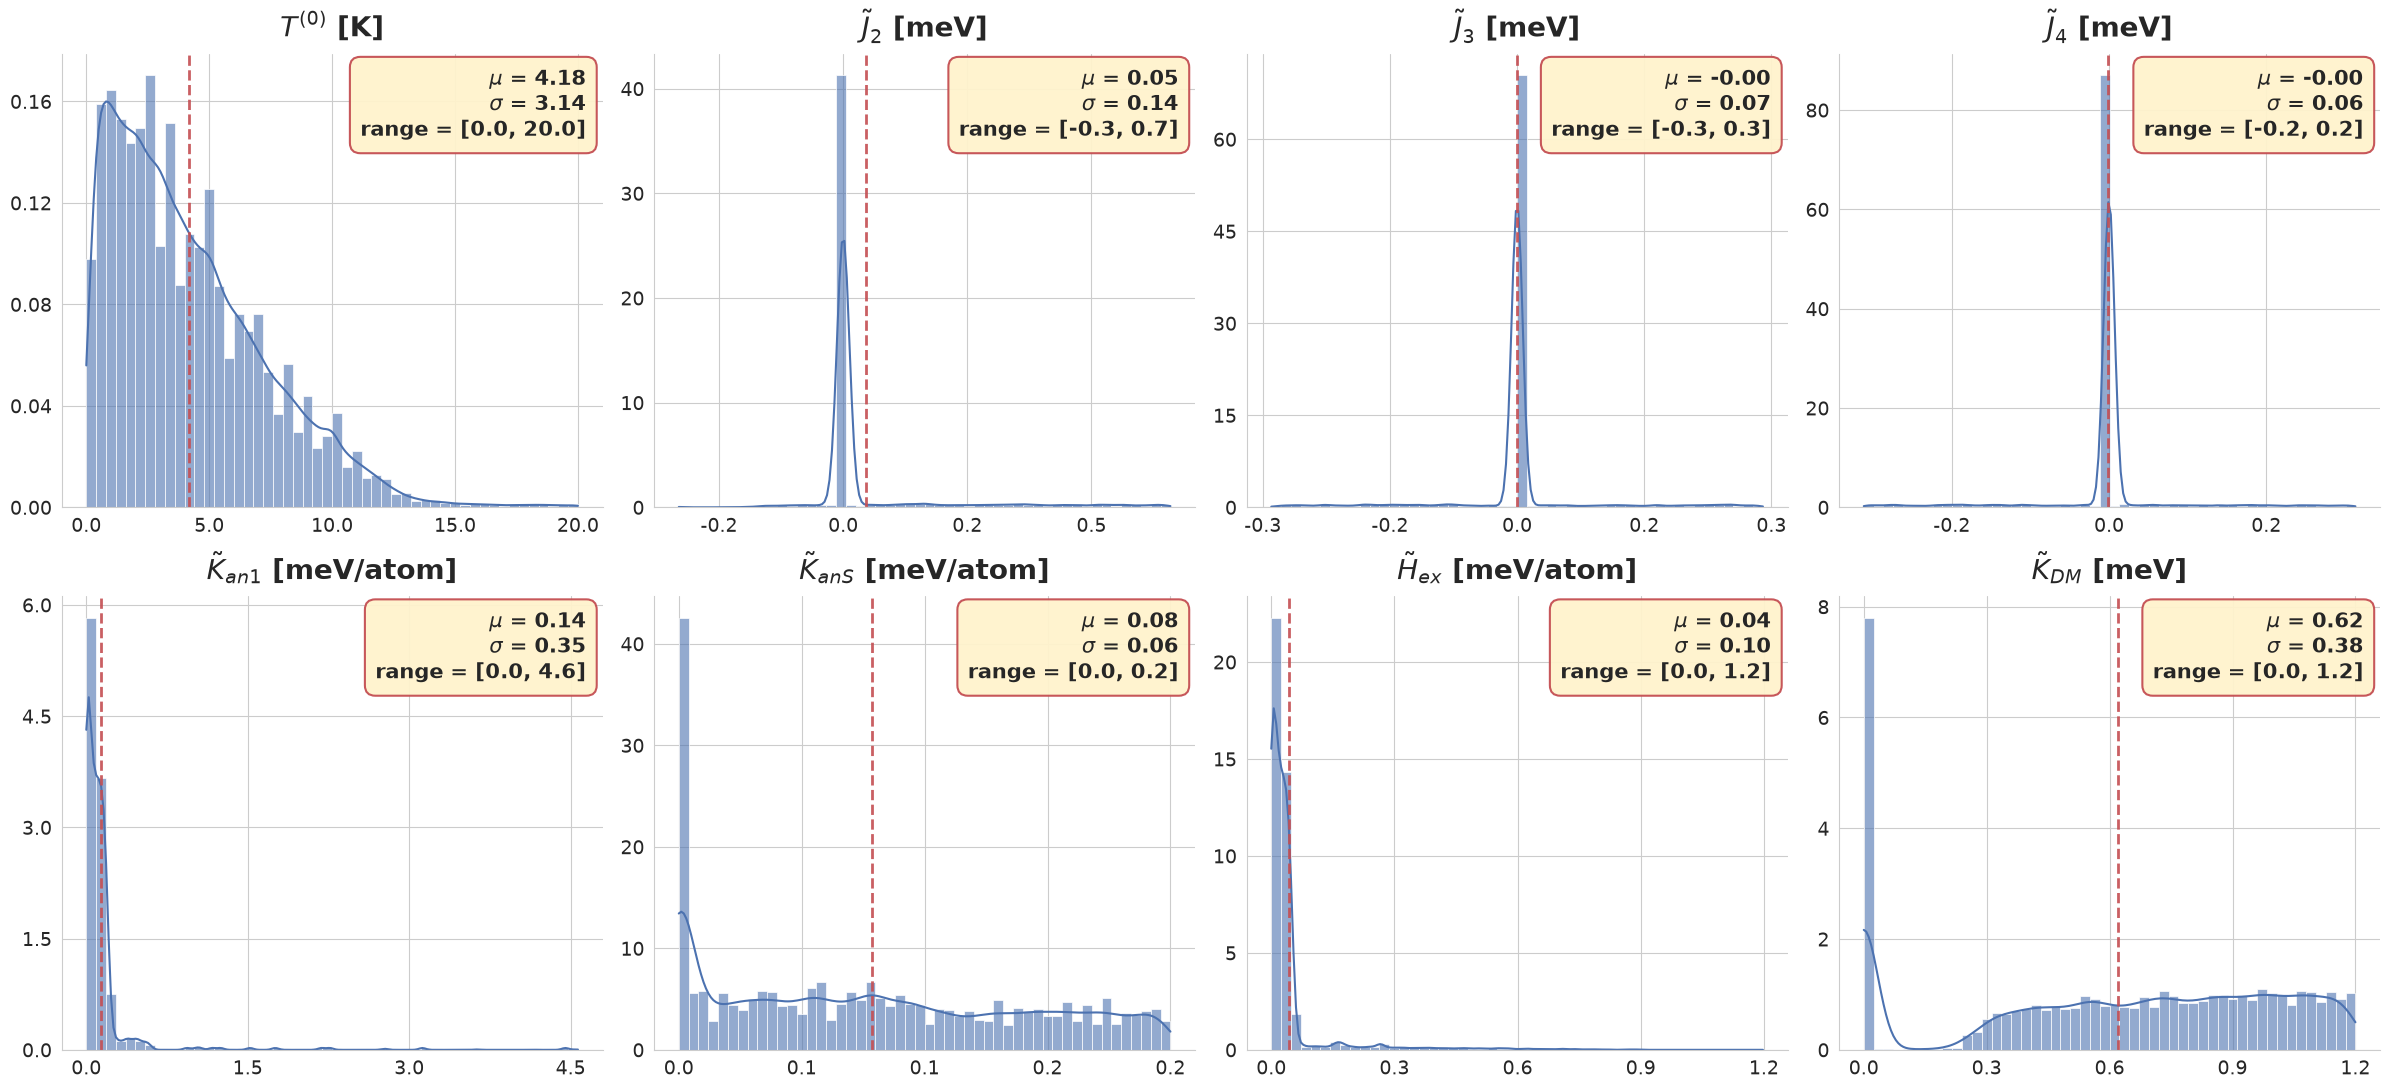

✅ Figura guardada en /workspace/Process/Images/parameter_distributions_kde.pdf


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(24, 11))
axes = axes.flatten()

for i, name in enumerate(param_names):
    ax = axes[i]
    vals = params[:, i]

    sns.histplot(vals, bins=50, kde=True, ax=ax,
                 color="#4C72B0", edgecolor="white",
                 alpha=0.6, stat="density", linewidth=0.5)

    mean = vals.mean()
    std  = vals.std()
    vmin = vals.min()
    vmax = vals.max()

    ax.axvline(mean, color="#C44E52", linestyle="--", linewidth=2.0, alpha=0.9)

    stats_text = (f"$\\mu$ = {mean:.2f}\n"
                  f"$\\sigma$ = {std:.2f}\n"
                  f"range = [{vmin:.1f}, {vmax:.1f}]")
    ax.text(0.97, 0.97, stats_text,
            transform=ax.transAxes,
            fontsize=15, fontweight="bold",
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle="round,pad=0.5",
                      facecolor="#FFF3CD", edgecolor="#C44E52",
                      linewidth=1.5, alpha=0.95))

    ax.set_title(param_labels[name], fontsize=20, fontweight="bold", pad=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis='both', labelsize=14)

    from matplotlib.ticker import MaxNLocator, FormatStrFormatter
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)
plt.savefig(f"{OUT_DIR}/parameter_distributions_kde.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Figura guardada en {OUT_DIR}/parameter_distributions_kde.pdf")

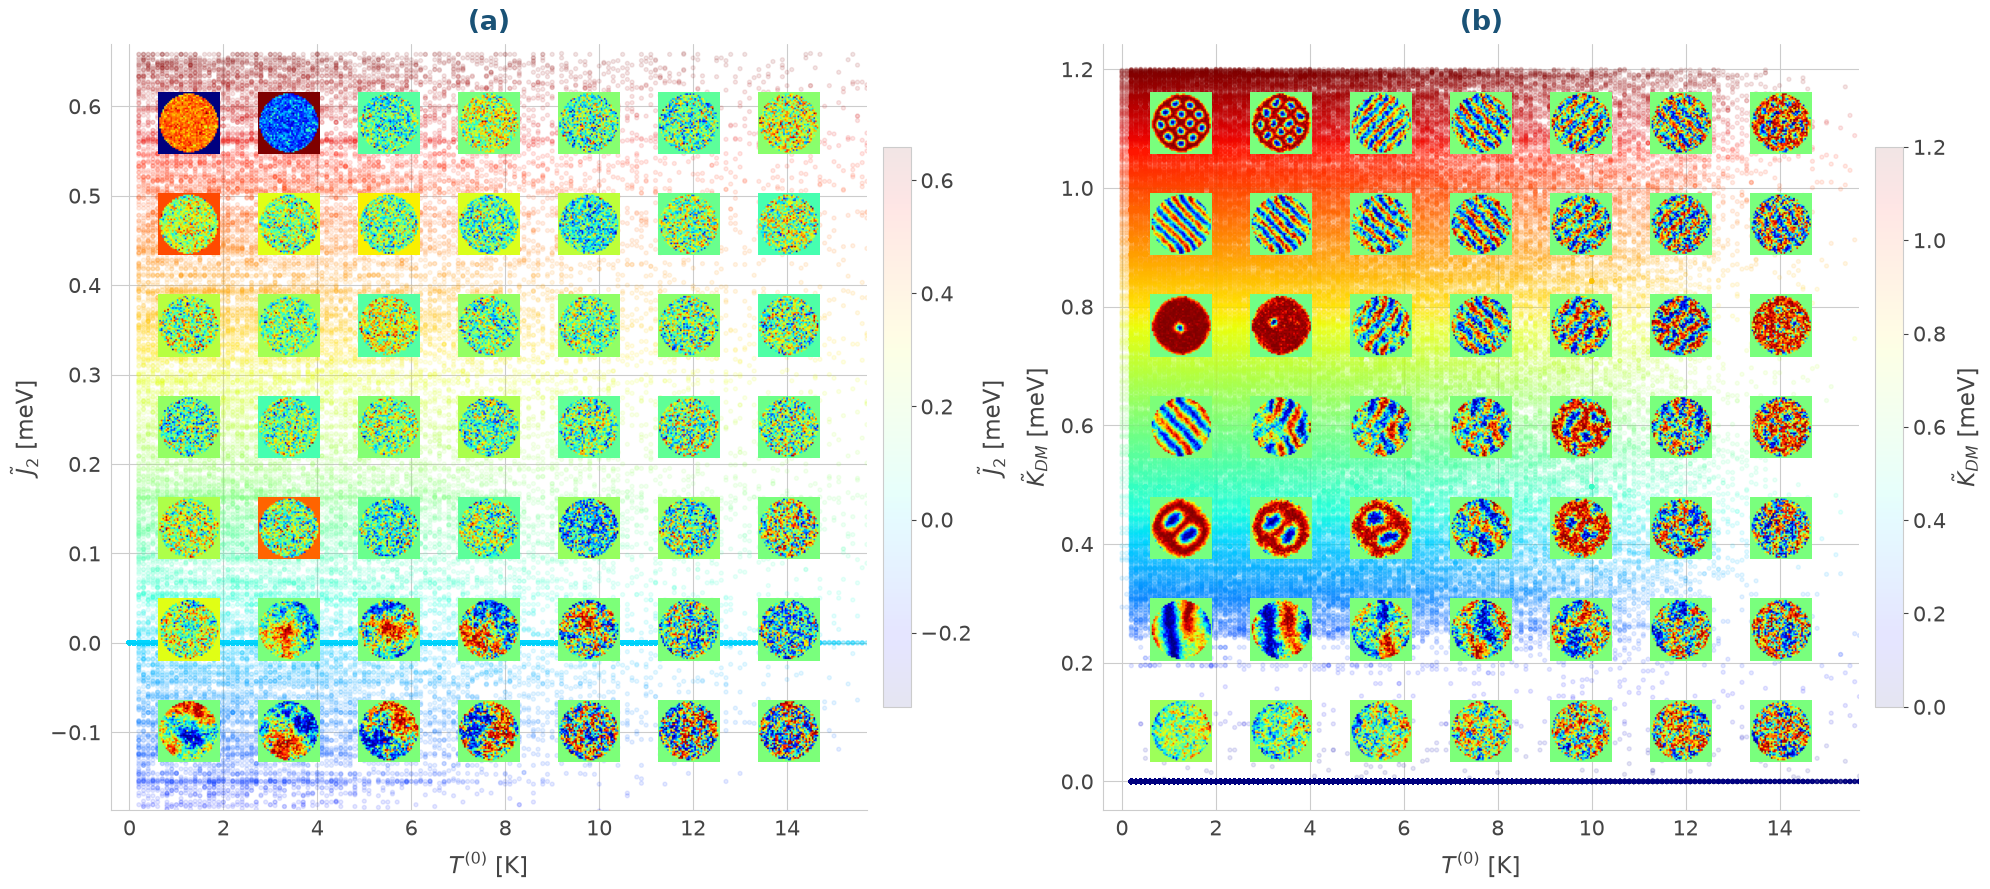

✅ Guardado en /workspace/Process/Images/phase_diagrams.pdf


In [6]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

IDX = {name: i for i, name in enumerate(param_names)}
if 'X' not in dir():
    _d = np.load(DATASET_PATH, allow_pickle=True)
    X = np.copy(_d['img']).astype(np.float32)

FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE; FS_LABEL = 11 * FONTSCALE; FS_TICK = 10 * FONTSCALE
c_line = "#1a5276"

T_vals    = params[:, IDX["T"]]
Jex2_vals = params[:, IDX["Jex2"]]
KDM_vals  = params[:, IDX["KDM"]]
images    = X.squeeze()
vmin, vmax = images.min(), images.max()

# ── MENOS y MÁS GRANDES: grilla 8×8, zoom 1.15 ──
nx = ny = 8
ZOOM = 1.15

fig, axes = plt.subplots(1, 2, figsize=(20, 9), facecolor='white')
panels = [
    (T_vals, Jex2_vals, r'$T^{(0)}$ [K]', r'$\tilde{J}_2$ [meV]', '(a)'),
    (T_vals, KDM_vals,  r'$T^{(0)}$ [K]', r'$\tilde{K}_{DM}$ [meV]', '(b)'),
]

for ax, (x_vals, y_vals, x_label, y_label, panel_label) in zip(axes, panels):
    ax.set_facecolor('white')

    # rango real de los datos (percentiles para ignorar outliers extremos)
    x_lo, x_hi = np.percentile(x_vals, [0.5, 99.5])
    y_lo, y_hi = np.percentile(y_vals, [0.5, 99.5])

    sc = ax.scatter(x_vals, y_vals, c=y_vals, cmap='jet',
                    alpha=0.10, s=8, zorder=1, rasterized=True)
    cb = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.02)
    cb.set_label(y_label, fontsize=FS_LABEL, color='#444444')
    cb.ax.tick_params(labelsize=FS_TICK, colors='#444444')

    # bins SOLO sobre el rango ocupado
    x_bins = np.linspace(x_lo, x_hi, nx)
    y_bins = np.linspace(y_lo, y_hi, ny)

    for i in range(nx - 1):
        for j in range(ny - 1):
            mask = ((x_vals >= x_bins[i]) & (x_vals < x_bins[i+1]) &
                    (y_vals >= y_bins[j]) & (y_vals < y_bins[j+1]))
            idx = np.where(mask)[0]
            if len(idx) == 0:
                continue
            # imagen MÁS CERCANA al centro de la celda (representativa, no aleatoria)
            x_c = (x_bins[i] + x_bins[i+1]) / 2
            y_c = (y_bins[j] + y_bins[j+1]) / 2
            d = ((x_vals[idx] - x_c) / (x_hi - x_lo))**2 + \
                ((y_vals[idx] - y_c) / (y_hi - y_lo))**2
            k = idx[np.argmin(d)]
            img_norm = (images[k] - vmin) / (vmax - vmin)
            im = OffsetImage(img_norm, cmap='jet', zoom=ZOOM)
            ab = AnnotationBbox(im, (x_c, y_c), frameon=False, zorder=2)
            ax.add_artist(ab)


    
    # límites ajustados al rango ocupado (sin espacios vacíos)
    pad_x = (x_hi - x_lo) * 0.04
    pad_y = (y_hi - y_lo) * 0.04
    ax.set_xlim(x_lo - pad_x, x_hi + pad_x)
    ax.set_ylim(y_lo - pad_y, y_hi + pad_y)

    ax.set_xlabel(x_label, color='#444444', fontsize=FS_LABEL, labelpad=8)
    ax.set_ylabel(y_label, color='#444444', fontsize=FS_LABEL, labelpad=8)
    ax.set_title(panel_label, fontsize=FS_TITLE, fontweight='bold', color=c_line, pad=10)
    ax.tick_params(colors='#444444', labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines['left'].set_color('#cccccc'); ax.spines['bottom'].set_color('#cccccc')

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/phase_diagrams.pdf", bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Guardado en {OUT_DIR}/phase_diagrams.pdf")